# Notebook para realizar preprocesamiento, configuración y entrenamiento de ANN   

- Estructura general de este notebook:

    1. Cargar **librerías** necesarias y configurar gráficas

    2. Definir **funciones** de utilidad

    3. **Preprocesamiento**
        - Cargar uno de los sets de datos generados en `data_exploration.ipynb`
        - Feature engineering: dos opciones
            - Seleccionar manualmente features y tipo de normalización    
            - Realizar un PCA y utilizar estandarización 

    4. Selección de **hiperparámetros** y definición del **modelo**
    
    5. **Entrenamiento** del modelo

    6. Realizar **predicciones** sobre el grupo de validación
    
    7. **Guardar de resultados** para reproducción y posterior análisis

- Adicionalmente, en la última sección se realizan perdicciones sobre el grupo de testeo y se plantean las gráficas para la comunicación de resultados

## Librerías y configuración de gráficas

In [1]:
import os
import pandas as pd
import numpy as np
import tensorflow as tf
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.metrics import r2_score

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input, Dropout
from tensorflow.keras.callbacks import ModelCheckpoint
from keras.optimizers import Adam, Adagrad, RMSprop

2025-10-20 18:55:38.638663: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2025-10-20 18:55:38.979177: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2025-10-20 18:55:40.617580: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [2]:
# Fijar tema para las gráficas
sns.set_theme(context='notebook', style='darkgrid', palette='colorblind')

# Fijar tamaño de la fuente
fs = 13.5

## Funciones de utilidad

In [3]:
# -------------------------------------

def sample_features(df_raw, features_selection_alias):
    '''
    Seleccionar features de acuerdo a un alias
    Estos grupos fueron construidos en base al análisis realizado en data_exploration.ipynb y a pruebas de entrenamiento
    realizadas utilizando este código
    
    Obs1: En ninguno de los casos se utiliza la variable z dado que este es el valor a predecir, ni tampoco 
    la variable zErr puesto que constituiría un data-leak y en consecuencia a un sobreajuste.

    Obs2: La elección de feature_selection_alias debe ser consistente con las columnas en df_raw. En caso de querer
    utilizar todas las columnas de df_raw, definir features_selection_alias='All'
    '''
    
    if features_selection_alias == 'A':
        features = ['ra','dec', 'decErr',
                    'dered_u', 'dered_g', 'dered_r','dered_i','dered_z',
                    'psfMag_u','psfMag_g', 'psfMag_r', 'psfMag_i', 'psfMag_z',
                    'psfMagErr_u', 'psfMagErr_g', 'psfMagErr_r', 'psfMagErr_i', 'psfMagErr_z',
                    'fiberMag_u', 'fiberMag_g','fiberMag_r', 'fiberMag_i', 'fiberMag_z',
                    'modelMag_u', 'modelMag_g', 'modelMag_r', 'modelMag_i', 'modelMag_z',
                    'expPhi_u','expPhi_g','expPhi_r','expPhi_i','expPhi_z',                                      
                    'petroRad_r']       #'expRad_g', 'expRad_i', 'expRad_r', 'expRad_z',  

    elif features_selection_alias == 'E':
        features = ['ra','dec','decErr', 
                    'dered_u', 'dered_g', 'dered_r','dered_i','dered_z',
                    'psfMag_u','psfMag_g', 'psfMag_r', 'psfMag_i', 'psfMag_z',
                    'fiberMag_u', 'fiberMag_g','fiberMag_r', 'fiberMag_i', 'fiberMag_z',
                    'modelMag_u', 'modelMag_g', 'modelMag_r', 'modelMag_i', 'modelMag_z']

    elif features_selection_alias == 'F':
        features = ['ra','dec','decErr', 
                    'dered_u', 'dered_g', 'dered_r','dered_i','dered_z',
                    'psfMag_u','psfMag_g', 'psfMag_r', 'psfMag_i', 'psfMag_z',
                    'fiberMag_u', 'fiberMag_g','fiberMag_r', 'fiberMag_i', 'fiberMag_z',
                    'psfMagErr_u', 'psfMagErr_g', 'psfMagErr_r', 'psfMagErr_i', 'psfMagErr_z',             
                    'modelMag_u', 'modelMag_g', 'modelMag_r', 'modelMag_i', 'modelMag_z']                   

    elif features_selection_alias == 'All':
        features = list(df_raw.columns[2:])         # Descartar z y zErr

    return features    

# -------------------------------------

def gen_rand_split(df_sel, val_p, test_p, SEED_val, SEED_test):
    '''
    Generar random split en base a:
        df_sel:    Dataframe con los features seleccionados + reshift z
        val_p:     Porcentaje para el grupo de validación
        test_p:    Porcentaje para el grupo de test
        SEED_val:  Semilla para el split train/val
        SEED_test: Semilla para el split (train + val) / test      
        '''

    # Separar features y label
    X = df_sel.drop('z', axis=1)
    y = df_sel['z']

    # Primer split: (train + val) / test 
    X_train_val, X_test, y_train_val, y_test = train_test_split(
        X, y, test_size=test_p, random_state=SEED_test)

    # Segundo split: train / val
    X_train, X_val, y_train, y_val = train_test_split(
        X_train_val, y_train_val, test_size=val_p/(1-test_p), random_state=SEED_val)

    return X_train, X_val, X_test, y_train, y_val, y_test

# -------------------------------------
def scaled_sigmoid(x):
    '''
    Definir activación para la capa de salida (para un rango 0 < z < 6)
    '''
    return 6. * tf.sigmoid(x)

# -------------------------------------


## Pre-procesamiento

**Cargar datos**

- Seleccionar path según input data (ver documentación sobre estos dataset)
- Seleccionar semilla

In [4]:
# --- 1. Cargar datos filtrados ---
path_to_data = 'clean1_150k.csv'
df_raw = pd.read_csv(path_to_data)

# --- 2. Fijar semillas ---
SEED = 42                           # Usanda para el test split y el resto de cálculos
SEED_val = 42                       # Usada solo para el validation split
np.random.seed(SEED)
tf.random.set_seed(SEED)

# --- 3. Seleccionar features --- 
features_selection_alias = 'All'                  # Alias: A, E, F, All
features = sample_features(df_raw, features_selection_alias)

# --- 4. Añadir redshift --- 
features.append('z')
df_sel = df_raw[features]

print(f"Data loaded from {path_to_data}\nFeatures selection alias: {features_selection_alias}\nGeneral seed set to {SEED}")


Data loaded from clean1_150k.csv
Features selection alias: All
General seed set to 42


**Split y normalización**:

- Seleccionar porcentajes para el train/val/test split
    - Utilizar la funciones definidas anteriormente

- Seleccionar scaler: MinMax, Standar, Robust

- Alternativamente: Implementar PCA sobre todas las variables

In [44]:
# --- Activar PCA y seleccionar cantidad de componentes --- 
PP_PCA = False
TARGET_COMPONENTS = 24 

#########
# PCA

if PP_PCA:

    from sklearn.decomposition import PCA

    # --- 1. Cargar datos y separar features/label ---
    df_raw = pd.read_csv('cleanA_150k.csv')
    y = df_raw['z']
    df_raw.drop(columns=['z','zErr'], inplace=True)

    N_FEATURES = len(df_raw.columns)
    N_SAMPLES = len(df_raw)

    X_df = df_raw

    # --- 2. Train/Val/test split --- 
    X_train_val, X_test, y_train_val, y_test = train_test_split(
        X_df, y, test_size=0.15, random_state=SEED
    )

    # - Separar train/val -
    X_train, X_val, y_train, y_val = train_test_split(
        X_train_val, y_train_val, test_size=0.2/0.85, random_state=SEED_val
    )

    print("-" * 70)
    print(f"Training set shape:   {X_train.shape}")
    print(f"Validation set shape: {X_val.shape}")
    print(f"Test set shape:       {X_test.shape}")
    print("-" * 70)

    # --- 3. Estandarizar entradas al PCA ---
    scaler_name = 'Standar'                         # Variable a guardar en archivo de salida
    feature_scaler = StandardScaler()
    X_train_scaled = feature_scaler.fit_transform(X_train)

    # - Aplicar esta transformación a los grupos de validación y testeo -
    X_val_scaled = feature_scaler.transform(X_val)
    X_test_scaled = feature_scaler.transform(X_test)

    # --- 4. Ajustar PCA en el grupo estandarizado de entrenamiento ---
    pca = PCA(n_components=TARGET_COMPONENTS)
    X_train_pca = pca.fit_transform(X_train_scaled)
    
    # - Aplicar el mismo PCA a los grupos de validación y testeo -
    X_val_pca = pca.transform(X_val_scaled)
    X_test_pca = pca.transform(X_test_scaled)
    
    # - Calcular cantidad de variabilidad explicada por las estas componentes -
    explained_variance = np.sum(pca.explained_variance_ratio_)
    print(f"Total variance explained by {TARGET_COMPONENTS} components (based on train data): {explained_variance:.4f}")
    
    # --- 5. Estandarizar la salida del PCA ---
    pca_scaler = StandardScaler()
    X_train_nn_input = pca_scaler.fit_transform(X_train_pca)

    # - Aplicar esta transformación a los grupos de validación y testeo -
    X_val_nn_input = pca_scaler.transform(X_val_pca)
    X_test_nn_input = pca_scaler.transform(X_test_pca)

    # - Resumen final - 
    print("-" * 70)
    print("\n--- Final Data Ready for Neural Network Training ---")
    print(f"Train Input Shape (Standardized PCA): {X_train_nn_input.shape}")
    print(f"Val Input Shape (Standardized PCA): {X_val_nn_input.shape}")
    print(f"Test Input Shape (Standardized PCA): {X_test_nn_input.shape}")

    # - Actualizar inputs -
    X_train_scaled = X_train_nn_input
    X_val_scaled = X_val_nn_input 
    X_test_scaled = X_test_nn_input 
    

###########
# No PCA

else:
    print('--- No PCA implemented ---')    

    # --- 1. Seleccionar porcentajes train/val/test split ---
    val_p, test_p = 0.2, 0.15          

    X_train, X_val, X_test, y_train, y_val, y_test = gen_rand_split(df_sel, 
                                                                    val_p, 
                                                                    test_p, 
                                                                    SEED_val=SEED_val,
                                                                    SEED_test=SEED)  

    # --- 2. Seleccionar Scaler ---
    scaler_name = 'MinMax'

    if scaler_name=='Standar':
        scaler = StandardScaler()
    elif scaler_name=='MinMax':
        scaler = MinMaxScaler() 
    elif scaler_name=='Robust':
        scaler=RobustScaler()

    # --- 3. Ajustar en X_train, luego trainformar los demás ---
    X_train_scaled = scaler.fit_transform(X_train)
    X_val_scaled = scaler.transform(X_val)
    X_test_scaled = scaler.transform(X_test)

    # - Resumen final -
    print(f"Data split: Train ({len(X_train)}), Validation ({len(X_val)}), Test ({len(X_test)}) samples.")
    print(f'Shape of Training data: {X_train_scaled.shape}')
    print(f"Data standardized using {scaler_name}Scaler")


--- No PCA implemented ---
Data split: Train (97488), Validation (29997), Test (22498) samples.
Shape of Training data: (97488, 65)
Data standardized using MinMaxScaler


In [12]:
X_train_scaled.shape

(97488, 65)

In [18]:
X_train

,dec,decErr,dered_g,dered_i,dered_r,dered_u,dered_z,deVRad_g,deVRad_i,deVRad_r,...,psfMag_i,psfMag_r,psfMag_u,psfMag_z,psfMagErr_g,psfMagErr_i,psfMagErr_r,psfMagErr_u,psfMagErr_z,ra
136744,47.840592,0.107227,22.07505,19.44705,20.48550,26.32929,19.12617,4.124527,0.795662,1.721006,...,20.52168,21.69909,24.57521,19.97426,0.230414,0.050217,0.090310,0.923512,0.116316,121.647794
76433,55.700489,0.182373,21.74022,19.38299,20.25045,22.53994,19.00653,2.123993,3.567609,4.157112,...,20.82117,21.75466,23.49603,20.12255,0.191019,0.054793,0.084316,0.452481,0.114524,136.792460
79612,-2.437117,0.095767,22.17778,19.51022,20.73296,26.24552,19.62729,5.618812,2.588632,3.474274,...,20.89234,22.20978,25.85678,21.01748,0.291681,0.077142,0.138477,0.669152,0.332091,179.503865
38717,14.151985,0.013966,19.39699,17.21391,17.77167,21.98177,16.86917,3.900985,3.792067,3.923464,...,19.09826,19.71126,22.90650,18.63070,0.045275,0.019297,0.022745,0.456423,0.033913,14.434629
103426,53.529995,0.022551,21.13528,19.53713,19.98437,24.24013,19.19604,0.152065,0.209623,0.432105,...,19.85751,20.31706,23.98251,19.48386,0.043119,0.026676,0.029174,0.686273,0.065953,135.234315
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2889,0.622879,0.005266,18.48921,16.93517,17.38096,20.36440,16.56026,1.814728,1.486751,1.541078,...,18.12677,18.60128,21.74075,17.69411,0.015804,0.016672,0.010953,0.103427,0.021858,230.784117
148010,66.181889,0.011883,18.12594,16.89289,17.29843,19.92163,16.63235,4.617673,2.518955,2.927067,...,18.48195,18.84515,21.58108,18.24516,0.020363,0.018233,0.017426,0.126044,0.034488,169.314022
109154,63.917860,0.044213,22.03787,19.50589,20.47680,24.34364,19.03378,0.807851,0.972669,1.098852,...,20.09094,21.06146,24.62768,19.59782,0.123011,0.030847,0.048960,0.886653,0.066133,208.329964
45997,13.621059,0.035964,20.61479,20.29863,20.41295,20.81808,20.16889,0.135093,0.533982,0.374560,...,20.56953,20.67148,21.10903,20.43217,0.033571,0.052992,0.042765,0.085562,0.154929,26.966646


<Axes: xlabel='expRad_g', ylabel='Density'>

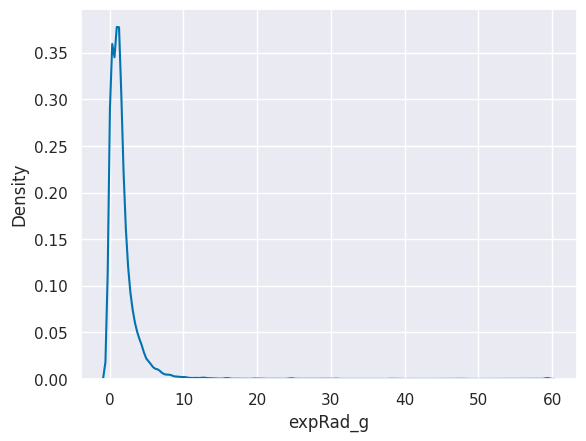

In [39]:
sns.kdeplot(X_train.iloc[:, 20])

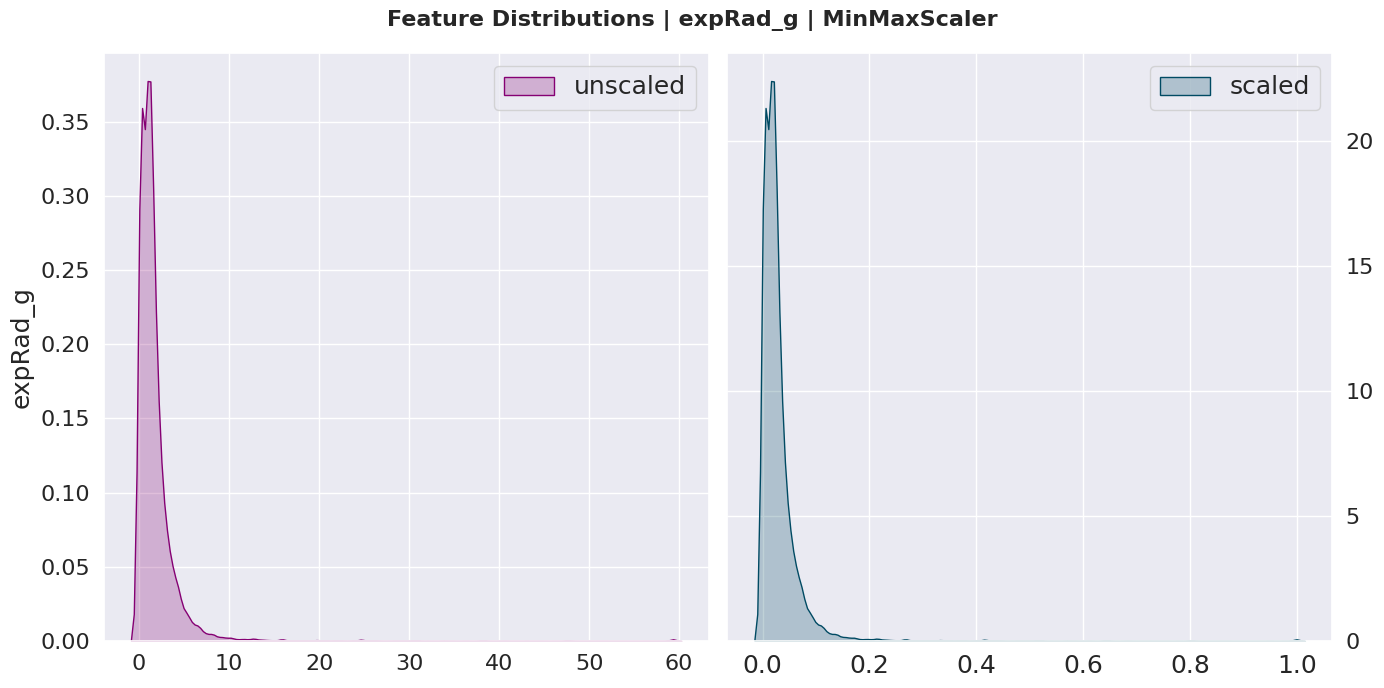

In [48]:
# Create the figure and shared subplots   (sharey=True)
fig, (ax_top, ax_bot) = plt.subplots(nrows=1, ncols=2, sharey=False, figsize=(14, 7))
plt.suptitle("Feature Distributions | expRad_g | MinMaxScaler", weight='bold', fontsize=16)

xmin, xmax = -5.2, 5.2

# colors
c1 = "#850073"
c2 = "#004A63"
c3 = "#DB6600"

# unscaled KDE
sns.kdeplot(X_train.iloc[:, 20], label='unscaled', ax=ax_top, color=c1, fill=True)

# Scaled KDE
sns.kdeplot(X_train_scaled[:, 20], label='scaled', ax=ax_bot, color=c2, fill=True)

ax_top.grid(True)
ax_top.tick_params(axis='y', which='both',labelbottom=False, labelsize=16,  
                   bottom=False, top=False, labeltop=False)   #labeltop=True       # Hide x-axis labels on the top plot
ax_top.tick_params(labelsize=16)
ax_top.set_ylabel('expRad_g', fontsize=18)
ax_top.set_xlabel('', fontsize=18)
ax_top.legend(fontsize=18)

ax_bot.grid(True)
ax_bot.tick_params(labelsize=18)
ax_bot.tick_params(axis='y', which='both',labelleft=False, labelsize=16,  
                   bottom=False, top=False, labelright=True) 
ax_bot.set_ylabel('')
ax_bot.legend(fontsize=18)

plt.subplots_adjust(wspace=0.0) 
plt.tight_layout()

#plt.savefig('dec_raw_MinMaxScaler_KDE.png', dpi=300)
plt.savefig('expRad_g_raw_MinMaxScaler_KDE.png', dpi=300)


In [50]:
y_train.shape, y_val.shape, y_test.shape

((97488,), (29997,), (22498,))

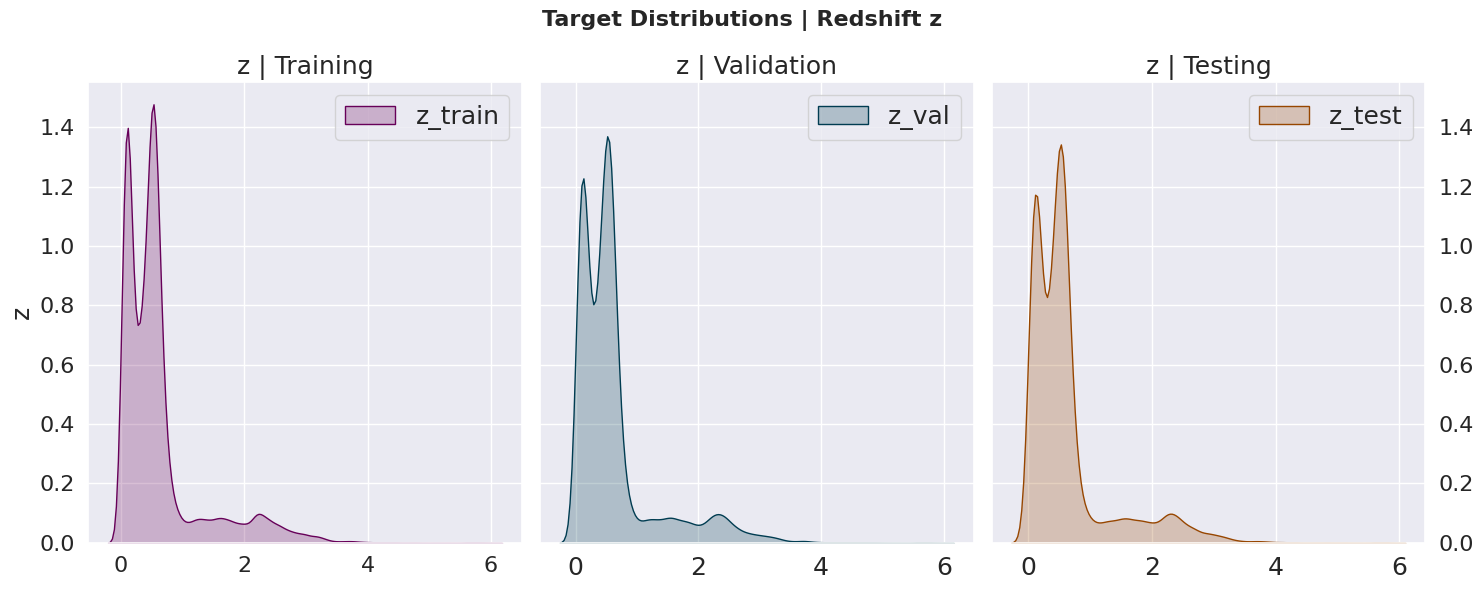

In [ ]:
# Create the figure and shared subplots   (sharey=True)
fig, (ax_top, ax_mid, ax_bot) = plt.subplots(nrows=1, ncols=3, sharey=True, figsize=(15, 6))
plt.suptitle("Target Distributions | Redshift z", weight='bold', fontsize=16)

xmin, xmax = -5.2, 5.2

# colors
c1 = "#670059"
c2 = "#003C51"
c3 = "#974600"

# z_train
sns.kdeplot(y_train, label='z_train', ax=ax_top, color=c1, fill=True)

# z_val
sns.kdeplot(y_val, label='z_val', ax=ax_mid, color=c2, fill=True)

# z_test
sns.kdeplot(y_test, label='z_test', ax=ax_bot, color=c3, fill=True)

ax_top.grid(True)
ax_top.set_title("z | Training", fontsize=18)
ax_top.tick_params(axis='y', which='both',labelbottom=False, labelsize=16,  
                   bottom=False, top=False, labeltop=False)   #labeltop=True       # Hide x-axis labels on the top plot
ax_top.tick_params(labelsize=16)
ax_top.set_ylabel('z', fontsize=18)
ax_top.set_xlabel('', fontsize=18)
ax_top.legend(fontsize=18)


ax_mid.grid(True)
ax_mid.set_title("z | Validation", fontsize=18)
ax_mid.tick_params(labelsize=18)
ax_mid.tick_params(axis='y', which='both',labelleft=False, labelsize=16,  
                   bottom=False, top=False, labelright=False) 
ax_mid.set_ylabel('')
ax_mid.set_xlabel('')
ax_mid.legend(fontsize=18)


ax_bot.grid(True)
ax_bot.set_title("z | Testing", fontsize=18)
ax_bot.tick_params(labelsize=18)
ax_bot.tick_params(axis='y', which='both',labelleft=False, labelsize=16,  
                   bottom=False, top=False, labelright=True) 
ax_bot.set_ylabel('')
ax_bot.set_xlabel('')
ax_bot.legend(fontsize=18)

plt.subplots_adjust(wspace=0.0) 
plt.tight_layout()

#plt.savefig('z_KDE_train_val_test_Robust.png', dpi=300)


## Modelo

- **Definición**:
    - Hiperparámetros: variables `HP_*`
    - Nombrar modelo 

- **Entrenamiento**

- **Evaluación**

In [35]:
def build_fnn_model(input_shape, units_hl, rates_dl, activation, output_activation='linear',
                    optimizer_name='adam', learning_rate=1e-3, loss_function='mse',metrics=['mae']):
    '''
    Construir Red Fully Connected en base a: 
    input_shape:        dimensiones de los vectores de entrada (i.e., cantidad de features)
    units_hl:           lista con la cantidad de neuronas por capa
    rates_dl:           lista con las tasas de dropout
    activation:         lista con las activaciones para las capas ocultas
    output_activation:  activación para la capa de salida   
    optimizer_name:     alias para el optimizador
    '''

    model = Sequential()
    
    # Capa de entrada (ancho igual a la cantidad de features)
    model.add(Input(shape=(input_shape,)))
    
    # Añadir capas ocultas
    for i in range(len(units_hl)):
        model.add(Dense(units=units_hl[i], 
                        activation=activation[i], 
                        name=f'Hidden_{i+1}'))
    
    # Condicional para añadir capa dropout
    if rates_dl[i] > 0.0:
        model.add(Dropout(rate=rates_dl[i], 
                          name=f'Dropout_{i+1}'))

    # Capa de salida (1 neurona)
    if output_activation=='scaled_sigmoid':
        model.add(Dense(1, activation=scaled_sigmoid, name='Output_Layer'))
    else:    
        model.add(Dense(1, activation=output_activation, name='Output_Layer'))

    # Definir optimizador
    if optimizer_name=='adam':
        optimizer = Adam(learning_rate=learning_rate)
    elif optimizer_name=='adagrad':
        optimizer = Adagrad(learning_rate=learning_rate)
    elif optimizer_name=='rmsprop':
        optimizer = RMSprop(learning_rate=learning_rate)            

    # Compilar modelo
    model.compile(optimizer=optimizer, loss=loss_function, metrics=metrics)
    return model

In [55]:
# --- Seleccionar hiperparámetros ---

HP_INPUT_SHAPE = X_train_scaled.shape[1]
HP_UNITS_HL = [64, 32, 16, 8]                               # Units for each layer
HP_RATES_DL = [0.3, 0.2, 0.1, 0.05]                        # Dropout Rates
HP_ACTIVATION = ['relu', 'tanh', 'tanh', 'softmax']             # Activation functions
HP_ACTIVATION_OUTPUT = 'linear'
HP_LOSS = 'mse'                                 # Loss function
HP_METRICS = ['mae']                            # Aditional metric
HP_OPTIMIZER = 'rmsprop'                           # Optimizer
HP_LR = 3e-3                                    # Learning rate
HP_EPOCHS = 450                                 # Epochs
HP_BATCH_SIZE = 512                             # Batch size

# --- Construir modelo ---
model = build_fnn_model(
    input_shape=HP_INPUT_SHAPE,
    units_hl=HP_UNITS_HL,
    rates_dl=HP_RATES_DL,
    activation=HP_ACTIVATION,
    output_activation=HP_ACTIVATION_OUTPUT,
    optimizer_name=HP_OPTIMIZER,
    learning_rate=HP_LR,
    loss_function=HP_LOSS,
    metrics=HP_METRICS
)

# --- Nombrar modelo e imprimir summary ---
model.name = 'Ro2_enc_65REP'                                                        
model.summary()                   

Model: "Ro2_enc_65REP"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Hidden_1 (Dense)                │ (None, 64)             │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Hidden_2 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Hidden_3 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Hidden_4 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout_4 (Dropout)             │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output_Layer (Dense)            │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,977 (27.25 KB)

 Trainable params: 6,977 (27.25 KB)

 Non-trainable params: 0 (0.00 B)

## Entrenamiento

- Selecionar boolean para configurar `ModelCheckpoint`
    - Opcionalmente utilizar `save_best_only=True`

- Entrenar modelo con los hiperparámetros definidos anteriormente

In [56]:
print(f"Starting training model {model.name}...")

# --- Definir checkpoint para guardar modelo ---
sbo = False              # Para guardar el modelo que presente mejor métrica (HP_METRICS)
cp = ModelCheckpoint(model.name+'.keras', save_best_only=sbo)        

history = model.fit(
    X_train_scaled, y_train,
    epochs=HP_EPOCHS,
    batch_size=HP_BATCH_SIZE,
    validation_data=(X_val_scaled, y_val),
    verbose=0,
    shuffle=True,
    callbacks=[cp]
)

print("Training finished.")

Starting training model Ro2_enc_65REP...
Training finished.


## Evaluación modelo

- **Evaluación** sobre el grupo de validación
- Calcular métricas

In [57]:
# Evaluar sobre el grupo de validación usando las mismas métricas del modelo
loss_val_final, met_val_final = model.evaluate(X_val_scaled, y_val, verbose=0)

# Predicciones y coeficiente de determinación
y_pred = model.predict(X_val_scaled)         
R2_val = r2_score(y_val, y_pred)

# Guardar función de pérdida en entrenamiento y validación
train_losses = history.history['loss'] 
val_losses = history.history['val_loss']

# Crear dataframe con features, labels y predicciones para posterior análisis         
df_val = pd.DataFrame(X_val_scaled, columns=features[:-1])
df_val['y_true'] = y_val.values
df_val['y_pred'] = y_pred.flatten()

print(f"Val Loss ({HP_LOSS}): {loss_val_final:.4f}\nVal Metric {HP_METRICS}: {met_val_final:.4f}\nVal R2: {R2_val:.4f}")

938/938 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
Val Loss (mse): 0.0837
Val Metric ['mae']: 0.1113
Val R2: 0.8210


## Guardar resultados

1. **Modelo** `.keras`

2. **Summary** `.txt`

3. **Descripción** `.md`

4. **Predicciones** `.csv`

5. **Métricas** `.csv`

5. **Gráficas** `.png`

In [58]:
# Solicitar el nombre del directorio de salida
model_name = model.name
folder_name = input("Output folder name: ")               # Por convención, el nombre del modelo 

# Definir la ruta base: Resultados/NOMBRE_DEL_MODELO
BASE_PATH = os.path.join('Resultados', folder_name)
os.makedirs(BASE_PATH, exist_ok=False)      # para evitar sobreescribir 

print(f"\nGuardando resultados críticos en: '{BASE_PATH}'")

# 0. Guardar modelo y predicciones sobre el grupo de validación
# modelo ya guardado anteriormente  

df_val.to_csv(os.path.join(BASE_PATH, f'val_predictions_{model.name}.csv'), index=False)
print(f"Predicciones guardadas en: val_predictions_{model.name}.csv")


# 1. Archivo de Descripción (README)
readme_content = f"""# Registro del Experimento: {model_name}

## Configuración Principal
- Neuronas:              {HP_UNITS_HL}
- Activaciones:          {HP_ACTIVATION}
- Activación salida:     {HP_ACTIVATION_OUTPUT}
- Dropouts:              {HP_RATES_DL}                      
- Estandarizacion:       {scaler_name}
- Nombre del Modelo:     {model_name}
- Loss:                  {HP_LOSS}
- Metrics                {HP_METRICS}
- Semilla global:        {SEED}
- Data entrada:          {path_to_data}
- Dimensión de Entrada:  {X_train_scaled.shape}
- Split (train% - val%): ({1-val_p-test_p}-{val_p})
- Epoch:                 {HP_EPOCHS}
- Bach_size:             {HP_BATCH_SIZE}
- Save_best_only         {sbo}
- Optimizador:           {HP_OPTIMIZER} 
- Learn_rate:            {HP_LR}
- Features:              {features[:-1]}
- PCA:                   {PP_PCA}
"""

# Guardar README en la carpeta del modelo
with open(os.path.join(BASE_PATH, f'README_{model_name}.md'), 'w') as f:
    f.write(readme_content)
print("Descripción guardada en: README.md")

# Guardar summary 
def write_summary_to_file(s):
    with open(os.path.join(BASE_PATH, f'model_{model_name}_summary.txt'), 'a') as f:  
        f.write(s + '\n')

model.summary(print_fn=write_summary_to_file)        

# Resultados (Métricas) sobre el grupo de validación
if HP_LOSS=='mse':
    results_data = {
        'Metric': ['RMSE', 'MSE', 'MAE', 'R2'],            
        'Value': [np.sqrt(loss_val_final), loss_val_final, met_val_final, R2_val]          
    }

elif HP_LOSS=='mae':
    results_data = {
        'Metric': ['MAE', 'R2', 'MSE', 'RMSE'],               
        'Value': [loss_val_final, R2_val, met_val_final,np.sqrt(met_val_final)]          
    }    

results_df = pd.DataFrame(results_data)

# Guardar CSV de métricas en la carpeta del modelo
results_df.to_csv(os.path.join(BASE_PATH, f'metrics_{model_name}.csv'), index=False)
print("Métricas guardadas en metrics.csv")

# Momentos sobre grupo de validación
y_pred = pd.Series(y_pred.flatten())        # Para poder aplicar momentos
moments_val = [y_val.mean(),y_val.var(),y_val.skew(),y_val.kurt()]
moments_pred = [y_pred.mean(),y_pred.var(),y_pred.skew(),y_pred.kurt()]

## Crer dataframe con los momentos
moments_df = pd.DataFrame([moments_val, moments_pred], 
                          columns=['Mean', 'Variance', 'Skewness', 'Kurtosis'], 
                          index=['TrueVal z', 'PredVal z'])

moments_df.to_csv(os.path.join(BASE_PATH, f'moments_{model_name}.csv'), index=False)
print("Momentos de PredVal y TrueVal guardados en moments.csv")


##### ----  GRÁFICAS  ----- ####

## Gráfica de Entrenamiento (Train/Val Loss)
plt.figure(figsize=(10, 6))
plt.plot(train_losses, label='Train Loss'+f' Last: {round(train_losses[-1],4)}')
plt.plot(val_losses, label='Validation Loss'+f' Last: {round(val_losses[-1],4)}')
#plt.plot(label=round(min(val_losses),4))
plt.title(f'Pérdida de Entrenamiento y Validación por Época | {model_name}', fontsize=fs)
plt.xlabel('Época', fontsize=fs)
plt.ylabel(f'Pérdida {HP_LOSS}', fontsize=fs)
plt.legend()
plt.grid(linestyle='--')
plt.savefig(os.path.join(BASE_PATH, f'train_val_loss_{model_name}.png'), dpi=300)
plt.close()
print("Gráfica de Pérdida guardada en train_val_loss.png")


#####
## Gráfica de dispersión True vs Pred sobre el grupo de validación
fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(y_val, y_pred, alpha=.08)         
ax.plot([0,6.2], [0, 6.2],linestyle='--', color='k')
ax.set_xlabel('TrueVal z', fontsize=fs)
ax.set_ylabel('PredVal z', fontsize=fs)
ax.set_title(f'Scatter Pred vs True | {model_name}', fontsize=fs)

ax.text(1, 5, f'{HP_LOSS}_val= {round(loss_val_final,4)}\n{HP_METRICS}_val= {round(met_val_final,4)}\nR2_val=  {round(R2_val,4)}',
        horizontalalignment='center',
        verticalalignment='center',
        bbox=dict(facecolor='yellow', alpha=0.5, boxstyle='round,pad=0.5'))

plt.grid(linestyle='--')
plt.savefig(os.path.join(BASE_PATH, f'ValScatter_{model_name}.png'), dpi=300)
plt.close()
print("Gráfica TrueVal vs PredVal guardada en ValScatter.png")


#####
## Gráfica de Distribución de Residuos (Histograma/KDE)
residuals = y_pred-y_val

plt.figure(figsize=(8, 5))
sns.kdeplot(residuals, color='purple',fill=True, alpha=0.5)
plt.title(f'KDE residuos sobre ValidationSet | {model_name}', fontsize=fs)
plt.xlabel('Residuos (pred-true)', fontsize=fs)
plt.ylabel('KDE', fontsize=fs)
plt.axvline(x=0, color='k', linestyle='--')
plt.grid(linestyle='--')
plt.savefig(os.path.join(BASE_PATH, f'KDE_residuos_{model_name}.png'), dpi=300)
plt.close()
print("Gráfica KDE de residuos guardada en KDE_residuos.png")

#####
## Gráfica de CDF Residuos
import matplotlib.ticker as ticker

fig, ax = plt.subplots(figsize=(8, 5))

sns.ecdfplot(residuals, complementary=False, color='red', linewidth=1.6)
ax.axvline(x=0, color='k', linestyle='--', linewidth=1.4)
ax.set_title(f'CDF residuos sobre ValidationSet | {model_name}', fontsize=fs)
ax.set_xlabel('y_pred-y_val', fontsize=fs)
ax.set_ylabel('CDF', fontsize=fs)
ax.xaxis.set_major_locator(ticker.MultipleLocator(1))
ax.grid(linestyle='-', color='k', axis='x', alpha=.45)

plt.savefig(os.path.join(BASE_PATH, f'CDF_residuos_{model_name}.png'), dpi=300)
plt.close()
print("Gráfica CDF de residuos guardada en CDF_residuos.png")


print("\nProceso finalizado.")

# Quizás agregar algún violin or box plot


Guardando resultados críticos en: 'Resultados/Ro2_enc_65REP'
Predicciones guardadas en: val_predictions_Ro2_enc_65REP.csv
Descripción guardada en: README.md


Métricas guardadas en metrics.csv
Momentos de PredVal y TrueVal guardados en moments.csv
Gráfica de Pérdida guardada en train_val_loss.png
Gráfica TrueVal vs PredVal guardada en ValScatter.png
Gráfica KDE de residuos guardada en KDE_residuos.png
Gráfica CDF de residuos guardada en CDF_residuos.png

Proceso finalizado.


## Una vez finalizada la exploración de modelos

- Planetar gráficas para el informe y generar predicciones sobre el grupo de testeo

### Gráficas para informe

- Cuadradas o dimensión 8,6
- dpi=300 mínimo
- Grid color gris para contrastar con el blanco del fondo
- fontsize=13 mínimo

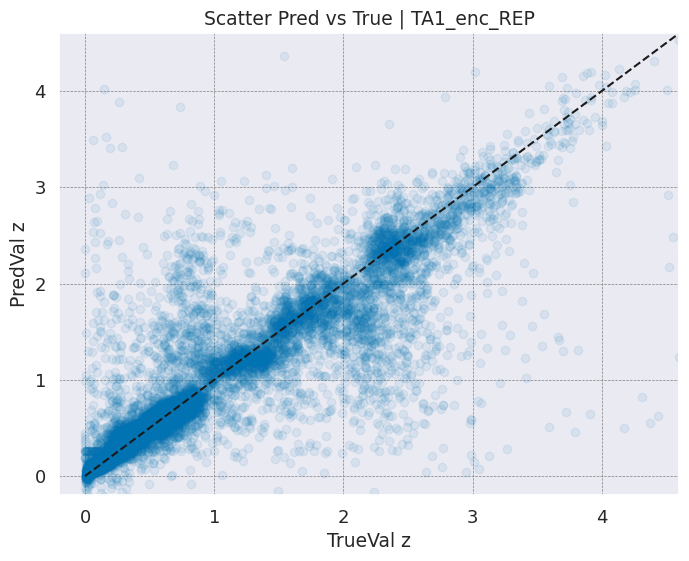

In [ ]:
# Gráfica para informe

## 2. Scatter pred vs true
fig, ax = plt.subplots(figsize=(8, 6))

ax.scatter(y_val, y_pred, alpha=.08)         
ax.plot([0,6.2], [0, 6.2],linestyle='--', color='k')
ax.set_xlabel('z-Spec (Validación)', fontsize=fs)
ax.set_ylabel('z-Pred (Validación))', fontsize=fs)
ax.set_title(f'Scatter Pred vs Real | {model_name}', fontsize=fs)

plt.grid(linestyle='--', linewidth=.5, color='gray')
ax.tick_params(axis='both', which='major', labelsize=13)

plt.ylim(-0.2,4.6)
plt.xlim(-0.2,4.6)
plt.savefig(os.path.join(BASE_PATH, f'Informe_ValScatter_{model_name}.png'), dpi=300)
#plt.close()
#print("Gráfica TrueVal vs PredVal guardada en ValScatter.png")

In [ ]:
# Gráfica para informe

## 1. Training
fig, ax = plt.subplots(figsize=(8, 6))

model_name = model.name
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Validation Loss')
plt.title(f'Pérdida de Entrenamiento y Validación por Época | {model_name[:-4]}', fontsize=fs)
plt.xlabel('Época', fontsize=fs)
plt.ylabel(f'Pérdida {HP_LOSS}', fontsize=fs)
plt.legend()
plt.grid(linestyle='--', linewidth=.5, color='gray')

ax.tick_params(axis='both', which='major', labelsize=13)

plt.savefig(f'Informe_train_val_loss_{model_name}.png', dpi=300)
#plt.savefig(os.path.join(BASE_PATH, f'Informe_train_val_loss_{model_name}.png'), dpi=300)

### Generar predicciones sobre el grupo de test

- **Obs**: Una vez utilizados estos datos, el modelo en cuestión ya no puede ser modificado

In [63]:
# Evaluar sobre el grupo de test usando las mismas métricas del modelo
loss_test, met_test = model.evaluate(X_test_scaled, y_test, verbose=0)

# Predicciones y coeficiente de determinación
y_pred = model.predict(X_test_scaled)         
R2_test = r2_score(y_test, y_pred)

# Crear dataframe con features, labels y predicciones para posterior análisis         
df_test = pd.DataFrame(X_test_scaled, columns=features[:-1])
df_test['y_true'] = y_test.values
df_test['y_pred'] = y_pred.flatten()

# Guardar resultados
df_test.to_csv(os.path.join(BASE_PATH, f'test_predictions_{model.name}.csv'), index=False)

print(f"Test Loss ({HP_LOSS}): {loss_test:.4f}\nTest Metric {HP_METRICS}: {met_test:.4f}\nTest R2: {R2_test:.4f}")

704/704 ━━━━━━━━━━━━━━━━━━━━ 0s 490us/step
Test Loss (mae): 0.0946
Test Metric ['mse']: 0.0796
Test R2: 0.8295


In [64]:
## Gráfica de dispersión True vs Pred sobre el grupo de test
import matplotlib.ticker as ticker

fig, ax = plt.subplots(figsize=(8, 8))

ax.scatter(y_test, y_pred.flatten(), alpha=.08)         
ax.plot([0,5.8], [0, 5.8],linestyle='--', color='k')
ax.set_xlabel('z (Etiquetas)', fontsize=fs)
ax.set_ylabel('z (Predicciones)', fontsize=fs)
ax.set_title(f'Scatter Pred vs True | {model_name} | Test', fontsize=fs)
#ax.xaxis.set_major_locator(ticker.MultipleLocator(.5))
#ax.yaxis.set_major_locator(ticker.MultipleLocator(.5))
ax.tick_params(axis='both', labelsize=fs+1) 

plt.grid(linestyle='--')
plt.savefig(os.path.join(BASE_PATH, f'TestScatter_{model_name}.png'), dpi=300)
plt.close()
print("Gráfica TrueTest vs PredTest guardada en TestScatter.png")
plt.show()

Gráfica TrueTest vs PredTest guardada en TestScatter.png
